# Notebook 02 — Exploratory Data Analysis TokoKita — KUNCI JAWABAN

**Dataset:** TokoKita (fiktif), toko online dengan 6 tabel: `customers`, `products`, `orders`, `order_items`, `marketing`, `web_events`.

**Cara memakai**
- **Google Colab:** File → Upload notebook → pilih file ini. Jalankan sel pertama, lalu upload 6 file CSV dari folder `latihan/data`.
- **Jupyter/VS Code di laptop:** buka langsung dari folder `latihan/python`; CSV dibaca otomatis dari `latihan/data`.

Notebook ini adalah EDA lengkap: kualitas data → tren → kategori → distribusi → pelanggan → funnel → insight.
> Revenue baris = `qty × harga_satuan × (1 − diskon)`. Pendapatan hanya dihitung dari order berstatus **selesai**.

In [1]:
import os
import pandas as pd
import numpy as np

# ── Google Colab: jalankan sel ini, lalu upload 6 file CSV dari folder latihan/data ──
try:
    from google.colab import files  # noqa
    if not os.path.exists("orders.csv"):
        files.upload()
except ImportError:
    pass

DATA = "" if os.path.exists("orders.csv") else "../data/"   # di laptop: notebook ada di latihan/python, CSV di latihan/data
customers   = pd.read_csv(DATA + "customers.csv",   parse_dates=["tgl_daftar"])
products    = pd.read_csv(DATA + "products.csv")
orders      = pd.read_csv(DATA + "orders.csv",      parse_dates=["tgl_order"])
order_items = pd.read_csv(DATA + "order_items.csv")
marketing   = pd.read_csv(DATA + "marketing.csv",   parse_dates=["minggu"])
web_events  = pd.read_csv(DATA + "web_events.csv",  parse_dates=["tanggal"])
print({n: len(d) for n, d in [("customers", customers), ("products", products), ("orders", orders),
                              ("order_items", order_items), ("marketing", marketing), ("web_events", web_events)]})

{'customers': 600, 'products': 40, 'orders': 1332, 'order_items': 2217, 'marketing': 288, 'web_events': 5030}


## 1. Gambaran umum
Tampilkan `info()` tabel orders dan `describe()` tabel order_items. Berapa rentang tanggal order?

In [2]:
orders.info()
print(orders.tgl_order.min(), '→', orders.tgl_order.max())
order_items.describe()

<class 'pandas.DataFrame'>
RangeIndex: 1332 entries, 0 to 1331
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   order_id      1332 non-null   str           
 1   customer_id   1332 non-null   str           
 2   tgl_order     1332 non-null   datetime64[us]
 3   status        1332 non-null   str           
 4   metode_bayar  1332 non-null   str           
dtypes: datetime64[us](1), str(4)
memory usage: 52.2 KB
2025-01-15 00:00:00 → 2026-10-30 00:00:00


,item_id,qty,harga_satuan,diskon
count,2217.000000,2217.000000,2217.000000,2217.000000
mean,1109.000000,1.310329,201802.886784,0.040866
std,640.137095,0.567029,143775.212608,0.067302
min,1.000000,1.000000,49000.000000,0.000000
25%,555.000000,1.000000,79000.000000,0.000000
50%,1109.000000,1.000000,189000.000000,0.000000
75%,1663.000000,2.000000,279000.000000,0.100000
max,2217.000000,3.000000,649000.000000,0.200000


## 2. Kualitas data
Cek: (a) duplikat `order_id`, (b) nilai kosong di setiap tabel, (c) qty ≤ 0 atau harga ≤ 0.

In [3]:
print('duplikat order_id:', orders.order_id.duplicated().sum())
for n, d in [('customers', customers), ('orders', orders), ('order_items', order_items)]:
    print(n, d.isna().sum().sum(), 'nilai kosong')
print('qty/harga tidak wajar:', ((order_items.qty <= 0) | (order_items.harga_satuan <= 0)).sum())

duplikat order_id: 0
customers 0 nilai kosong
orders 0 nilai kosong
order_items 0 nilai kosong
qty/harga tidak wajar: 0


## 3. Siapkan tabel analisis
Gabungkan `order_items` + `orders` + `products` + `customers` menjadi `df`, tambahkan kolom `revenue`, `laba_kotor` (revenue − qty×hpp), dan `bulan` (YYYY-MM). Filter hanya order **selesai**.

In [4]:
df = (order_items.merge(orders, on='order_id').merge(products, on='product_id').merge(customers, on='customer_id'))
df = df[df.status == 'selesai'].copy()
df['revenue'] = df.qty * df.harga_satuan * (1 - df.diskon)
df['laba_kotor'] = df.revenue - df.qty * df.hpp
df['bulan'] = df.tgl_order.dt.strftime('%Y-%m')
df.head()

,item_id,order_id,product_id,qty,harga_satuan,diskon,customer_id,tgl_order,status,metode_bayar,...,harga,hpp,nama,gender,kota,tgl_daftar,channel_akuisisi,revenue,laba_kotor,bulan
0,1,O00001,P40,1,219000,0.0,C0001,2025-01-15,selesai,Transfer Bank,...,219000,151000,Sari Lestari,P,Jakarta,2025-01-12,Organik,219000.0,68000.0,2025-01
1,2,O00002,P25,1,79000,0.1,C0002,2025-01-19,selesai,Transfer Bank,...,79000,45000,Kartika Rahman,P,Palembang,2025-01-13,TikTok,71100.0,26100.0,2025-01
2,3,O00002,P21,1,99000,0.1,C0002,2025-01-19,selesai,Transfer Bank,...,99000,40000,Kartika Rahman,P,Palembang,2025-01-13,TikTok,89100.0,49100.0,2025-01
3,4,O00003,P05,1,349000,0.0,C0003,2025-01-22,selesai,E-Wallet,...,349000,184000,Agus Gunawan,P,Surabaya,2025-01-16,Instagram,349000.0,165000.0,2025-01
4,5,O00003,P27,2,159000,0.0,C0003,2025-01-22,selesai,E-Wallet,...,159000,100000,Agus Gunawan,P,Surabaya,2025-01-16,Instagram,318000.0,118000.0,2025-01


## 4. Tren revenue bulanan
Buat line chart revenue per bulan. Beri judul berupa **insight**.

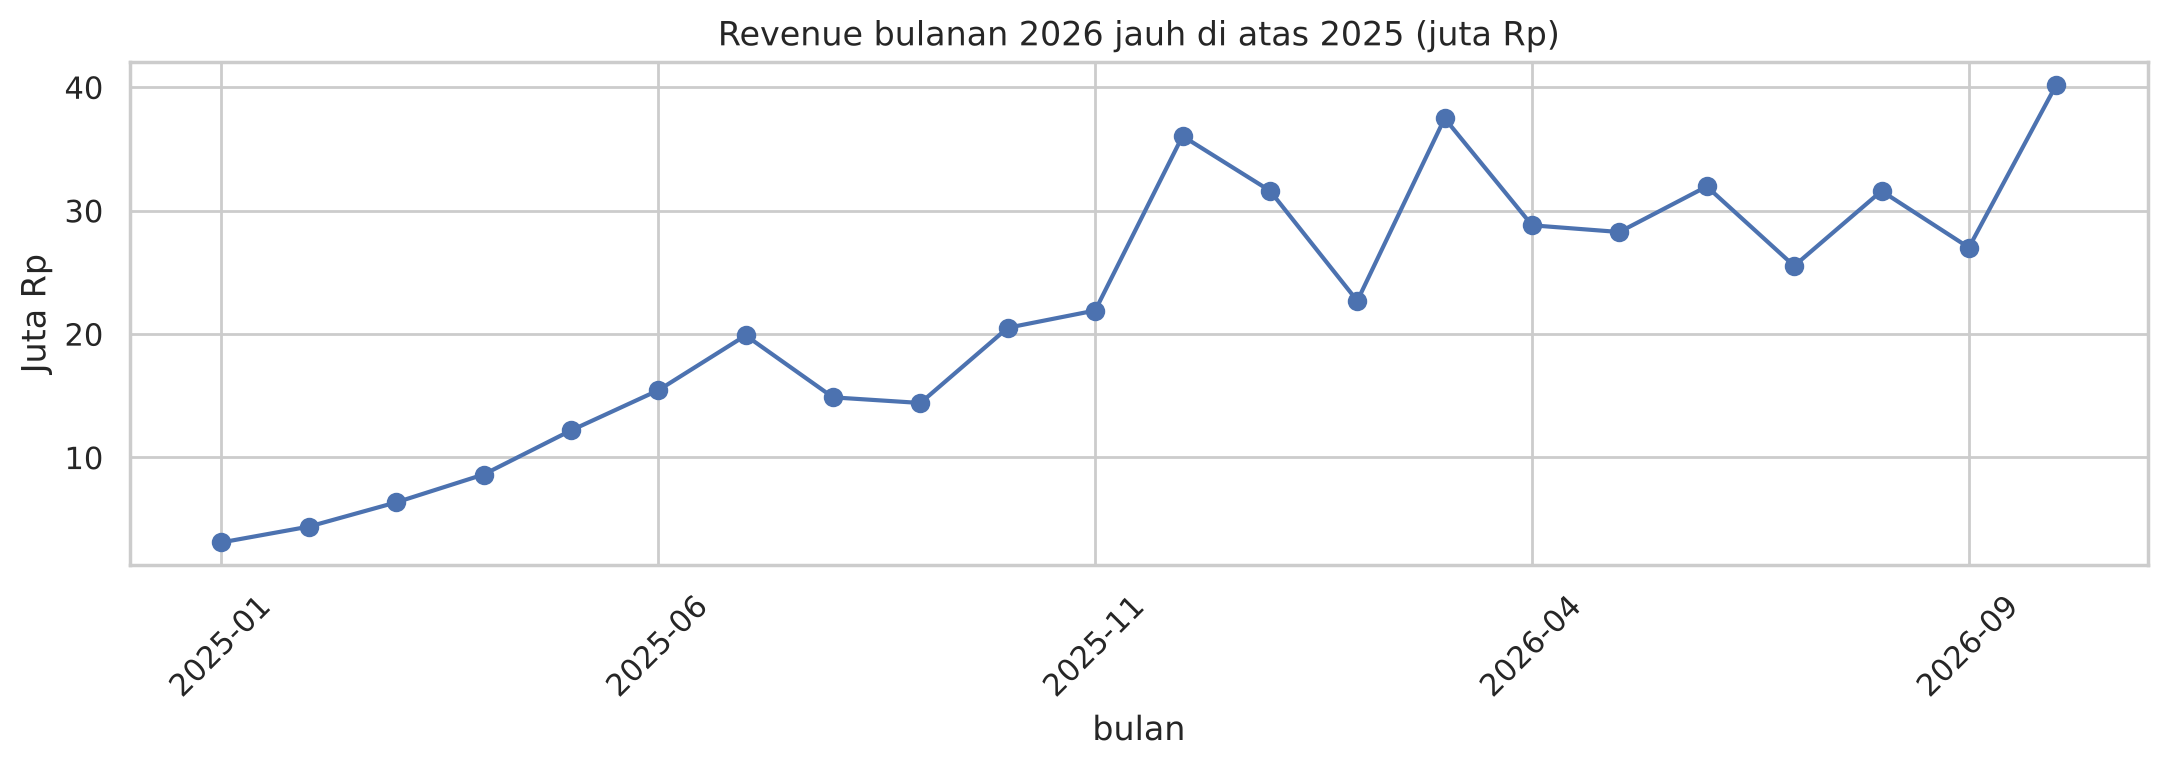

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')
bulanan = df.groupby('bulan')['revenue'].sum() / 1e6
ax = bulanan.plot(marker='o', figsize=(11, 4))
ax.set_title('Revenue bulanan 2026 jauh di atas 2025 (juta Rp)')
ax.set_ylabel('Juta Rp'); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 5. Kategori: revenue & margin
Buat tabel per kategori berisi revenue, laba kotor, gross margin %. Visualkan revenue dengan bar chart horizontal terurut.

,revenue,laba,gm_pct
kategori,,,
Elektronik,145574900.0,25942900.0,17.8
Rumah Tangga,119210400.0,43845400.0,36.8
Fashion,91841100.0,38798100.0,42.2
Olahraga,85639600.0,27066600.0,31.6
Kecantikan,40612400.0,22450400.0,55.3


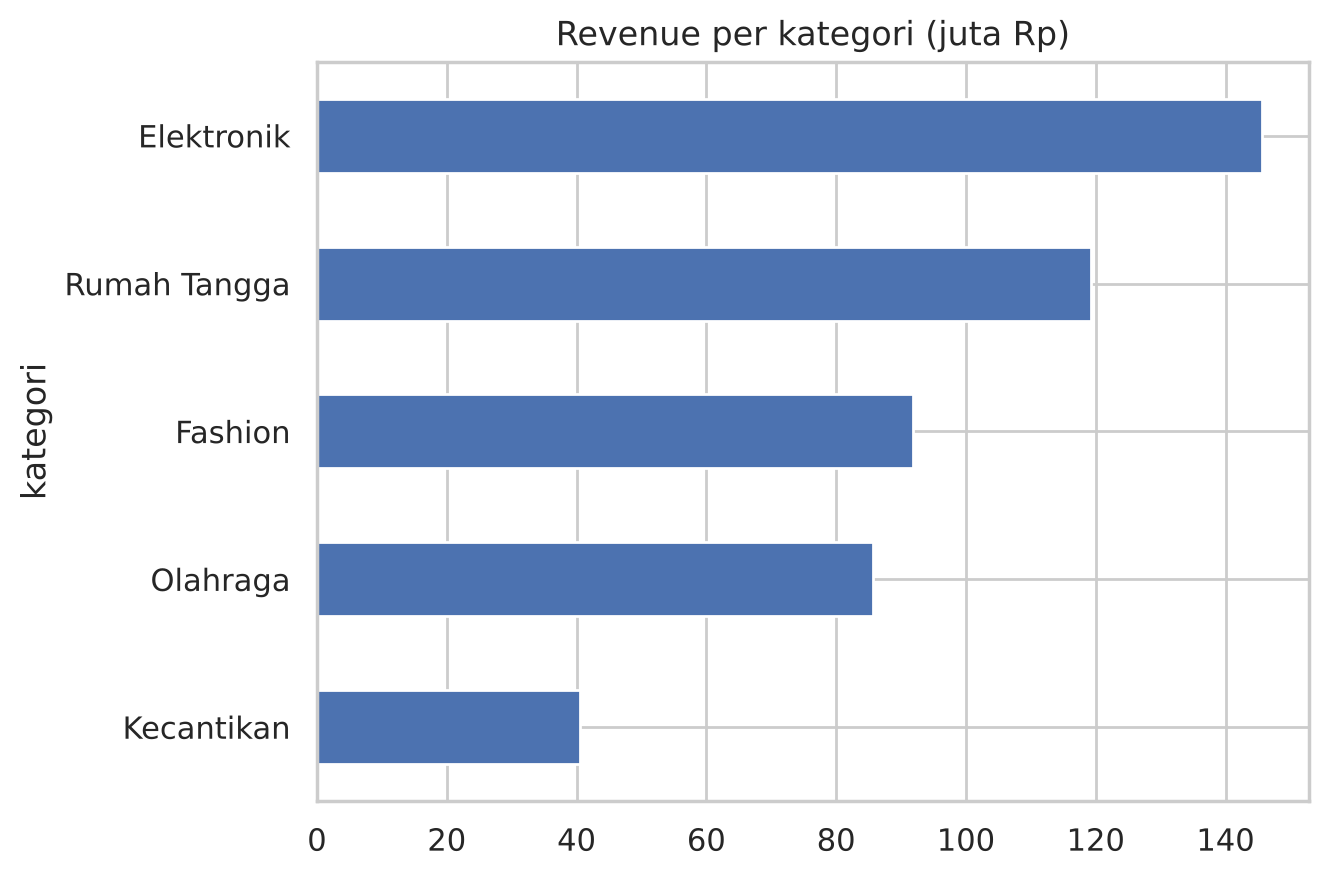

In [6]:
kat = df.groupby('kategori').agg(revenue=('revenue', 'sum'), laba=('laba_kotor', 'sum'))
kat['gm_pct'] = (kat.laba / kat.revenue * 100).round(1)
display(kat.sort_values('revenue', ascending=False))
kat.revenue.sort_values().div(1e6).plot(kind='barh', title='Revenue per kategori (juta Rp)'); plt.show()

## 6. Distribusi nilai order
Hitung nilai per order, lalu buat histogram & box plot. Bandingkan mean vs median: miring ke mana?

mean 416274 median 314100


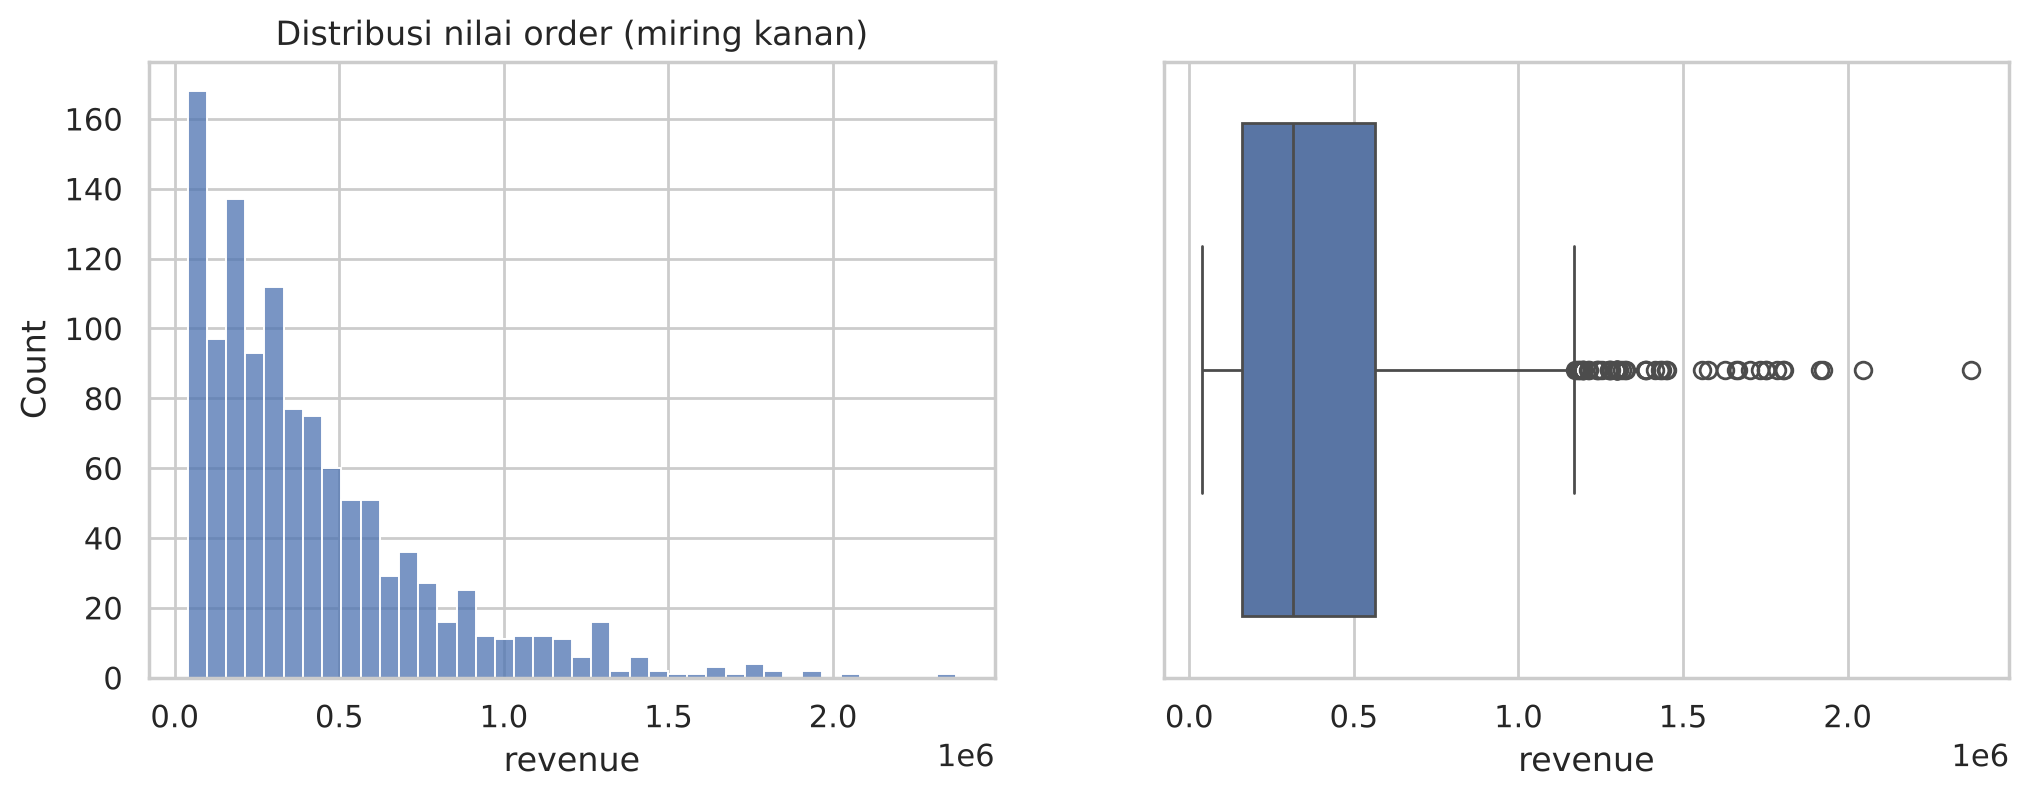

In [7]:
nilai = df.groupby('order_id')['revenue'].sum()
print('mean', round(nilai.mean()), 'median', round(nilai.median()))
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(nilai, bins=40, ax=ax[0]); ax[0].set_title('Distribusi nilai order (miring kanan)')
sns.boxplot(x=nilai, ax=ax[1]); plt.show()

## 7. Pelanggan per channel akuisisi
Per channel_akuisisi: jumlah pelanggan, rata-rata total belanja per pelanggan, % pelanggan repeat (≥ 2 order).

In [8]:
per_c = df.groupby(['customer_id', 'channel_akuisisi']).agg(belanja=('revenue', 'sum'), n_order=('order_id', 'nunique')).reset_index()
ringkas = per_c.groupby('channel_akuisisi').agg(pelanggan=('customer_id', 'count'), rata_belanja=('belanja', 'mean'), repeat_pct=('n_order', lambda s: (s >= 2).mean() * 100)).round(1)
ringkas.sort_values('rata_belanja', ascending=False)

,pelanggan,rata_belanja,repeat_pct
channel_akuisisi,,,
Referral,80,1089731.2,68.8
Organik,144,940405.6,62.5
Google Ads,98,938722.4,53.1
Instagram,124,755221.8,46.8
TikTok,118,632535.6,36.4


## 8. Funnel per device
Dari `web_events`, hitung jumlah sesi unik per langkah & device, lalu conversion view → purchase.

In [9]:
f = web_events.pivot_table(index='device', columns='event', values='session_id', aggfunc='nunique')[['view_product', 'add_to_cart', 'checkout', 'purchase']]
f['conv_pct'] = (f.purchase / f.view_product * 100).round(2)
f

event,view_product,add_to_cart,checkout,purchase,conv_pct
device,,,,,
desktop,858,338,230,170,19.81
mobile,2142,685,371,236,11.02


## 9. Tulis 5 insight
Gunakan format **Observasi → Kemungkinan penyebab → Tindak lanjut**.

In [10]:
# Contoh insight (versi kunci):
# 1. Elektronik menyumbang revenue terbesar tetapi margin terendah → dorong bundling aksesoris.
# 2. Conversion mobile jauh di bawah desktop, terutama di langkah checkout → audit UX checkout mobile.
# 3. Pelanggan Referral & Organik lebih sering repeat → perkuat program referral.
# 4. Nilai order miring kanan (mean > median) → laporkan median untuk 'order tipikal'.
# 5. Revenue tumbuh di 2026 seiring pelanggan baru → pantau retensi agar pertumbuhan berkelanjutan.
print('Lihat komentar di sel ini')

Lihat komentar di sel ini


---
Bandingkan dengan jawabanmu. Ingat: ada banyak cara benar untuk menulis kode yang sama.